In [18]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configuración estilo visual 
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

def cargar_datos_desde_sqlite(db_path='../data/coyuntura.db'):
    """Carga y pivotea la serie de tiempo desde la base relacional SQLite adaptándose al esquema."""
    if not os.path.exists(db_path):
        if os.path.exists('data/coyuntura.db'):
            db_path = 'data/coyuntura.db'
        else:
            raise FileNotFoundError(
                f"Error: No se encontró la base de datos en {db_path}. "
                "Asegúrate de ejecutar 'python src/carga_db.py' primero."
            )
    
    conn = sqlite3.connect(db_path)
    
    # Leer las dos tablas directamente
    df_obs = pd.read_sql_query("SELECT * FROM observaciones", conn)
    df_series = pd.read_sql_query("SELECT * FROM series", conn)
    conn.close()
    
    # Identificar automáticamente los nombres de las columnas
    col_nombre = [c for c in df_series.columns if 'nombre' in c or 'titulo' in c or 'descripcion' in c][0]
    id_series_col = [c for c in df_series.columns if 'id' in c or 'codigo' in c or 'serie' in c][0]
    fk_obs_col = [c for c in df_obs.columns if c in df_series.columns or 'id' in c or 'serie' in c][0]
    
    col_fecha = [c for c in df_obs.columns if 'fecha' in c or 'date' in c][0]
    col_valor = [c for c in df_obs.columns if 'valor' in c or 'value' in c][0]
    
    # Fusionar ambas tablas en Pandas
    df_merged = pd.merge(
        df_obs, 
        df_series, 
        left_on=fk_obs_col, 
        right_on=id_series_col
    )
    
    # Pivotear la tabla para tener las fechas en filas y cada serie en una columna
    df_pivot = df_merged.pivot(index=col_fecha, columns=col_nombre, values=col_valor)
    df_pivot.index = pd.to_datetime(df_pivot.index)
    return df_pivot

In [19]:
# Carga de datos desde SQLite
df_coyuntura = cargar_datos_desde_sqlite()

print("=== SERIES CARGADAS DESDE COYUNTURA.DB ===")
for i, col in enumerate(df_coyuntura.columns):
    print(f"{i+1}. {col}")

# Función auxiliar para identificar columnas
def obtener_columna(df, palabras_clave):
    for col in df.columns:
        if any(p.lower() in col.lower() for p in palabras_clave):
            return col
    return df.columns[0] 
col_tpm = obtener_columna(df_coyuntura, ['tpm', 'politica monetaria', 'tasa'])
col_ipc = obtener_columna(df_coyuntura, ['ipc', 'inflacion', 'interanual'])
col_sae = obtener_columna(df_coyuntura, ['sae', 'subyacente'])
col_eee = obtener_columna(df_coyuntura, ['eee', 'expectativa', '24m'])
col_imacec = obtener_columna(df_coyuntura, ['imacec', 'actividad'])
col_desempleo = obtener_columna(df_coyuntura, ['desempleo', 'desocupacion'])
col_fed = obtener_columna(df_coyuntura, ['fed', 'funds', 'estados unidos'])
col_usd = obtener_columna(df_coyuntura, ['usd', 'clp', 'dolar', 'tipo de cambio'])

=== SERIES CARGADAS DESDE COYUNTURA.DB ===
1. Bono del Tesoro EE.UU. a 10 años
2. Expectativas de inflación a 2 años (EEE)
3. Fed Funds Rate (tasa de política EE.UU.)
4. IMCE - Índice Mensual de Confianza Empresarial
5. IPC, variación mensual (calcular interanual con LAG 12 en SQL)
6. Imacec (índice)
7. Precio del cobre refinado BML
8. Tasa de Política Monetaria (TPM)
9. Tasa de desempleo nacional
10. Tipo de cambio nominal observado (CLP/USD)
11. Términos de intercambio


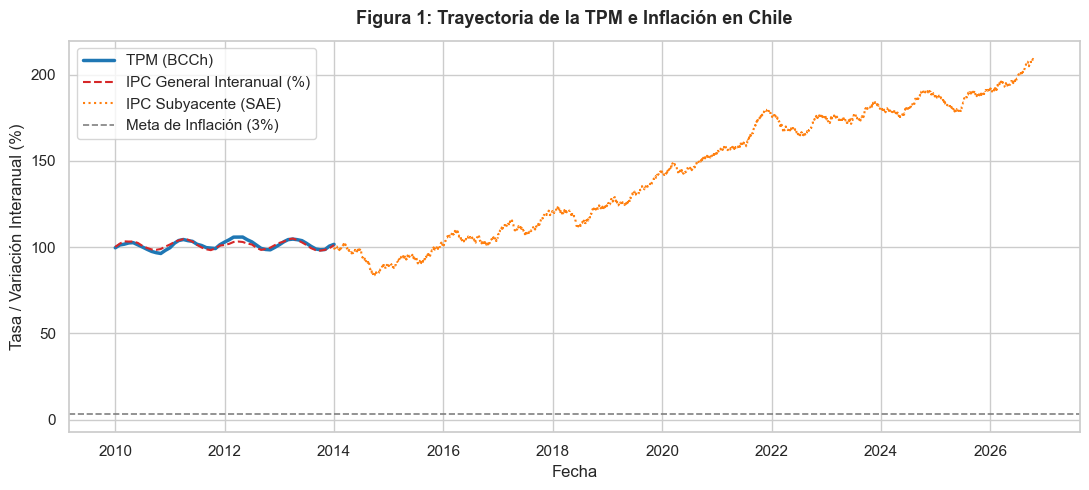

In [20]:
# GRÁFICO 1: TPM vs Inflación Observada y Meta (3%)
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(df_coyuntura.index, df_coyuntura[col_tpm], label='TPM (BCCh)', color='#1f77b4', linewidth=2.5)
if col_ipc in df_coyuntura.columns:
    ax1.plot(df_coyuntura.index, df_coyuntura[col_ipc], label='IPC General Interanual (%)', color='#d62728', linestyle='--')
if col_sae in df_coyuntura.columns:
    ax1.plot(df_coyuntura.index, df_coyuntura[col_sae], label='IPC Subyacente (SAE)', color='#ff7f0e', linestyle=':')

ax1.axhline(3.0, color='gray', linestyle='--', linewidth=1.2, label='Meta de Inflación (3%)')

ax1.set_title("Figura 1: Trayectoria de la TPM e Inflación en Chile", fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel("Tasa / Variación Interanual (%)")
ax1.set_xlabel("Fecha")
ax1.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

###  Análisis de Coyuntura: Figura 1
* **Título:** Trayectoria de la Tasa de Política Monetaria (TPM) e Inflación Observada.
* **Fuente:** Banco Central de Chile (extraído desde base local `coyuntura.db`).
* **Lectura Económica:** 
La Figura 1 ilustra la respuesta de la postura monetaria ante la dinámica inflacionaria en Chile. Se aprecia cómo el Banco Central ajustó restrictivamente la TPM para contener presiones inflacionarias situadas sustancialmente por sobre la meta del $3\%$, iniciando posteriormente un ciclo de recortes y normalización monetaria a medida que tanto la inflación general como la subyacente convergieron de regreso al centro del rango meta.

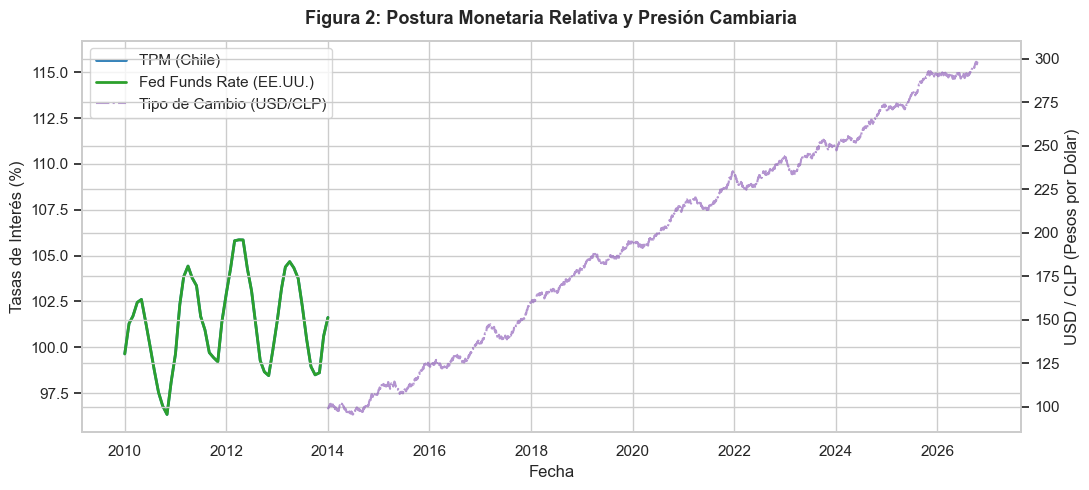

In [21]:
# GRÁFICO 2: Canal Externo - TPM vs Fed Funds Rate y Dólar
fig, ax2_left = plt.subplots(figsize=(11, 5))
ax2_right = ax2_left.twinx()

ax2_left.plot(df_coyuntura.index, df_coyuntura[col_tpm], label='TPM (Chile)', color='#1f77b4', linewidth=2)
if col_fed in df_coyuntura.columns:
    ax2_left.plot(df_coyuntura.index, df_coyuntura[col_fed], label='Fed Funds Rate (EE.UU.)', color='#2ca02c', linewidth=2)
if col_usd in df_coyuntura.columns:
    ax2_right.plot(df_coyuntura.index, df_coyuntura[col_usd], label='Tipo de Cambio (USD/CLP)', color='#9467bd', linestyle='-.', alpha=0.7)

ax2_left.set_title("Figura 2: Postura Monetaria Relativa y Presión Cambiaria", fontsize=13, fontweight='bold', pad=12)
ax2_left.set_ylabel("Tasas de Interés (%)")
ax2_right.set_ylabel("USD / CLP (Pesos por Dólar)")
ax2_left.set_xlabel("Fecha")

lines_1, labels_1 = ax2_left.get_legend_handles_labels()
lines_2, labels_2 = ax2_right.get_legend_handles_labels()
ax2_left.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

###  Análisis de Coyuntura: Figura 2
* **Título:** Postura Monetaria Relativa (TPM vs. Fed Funds) y Tipo de Cambio USD/CLP.
* **Fuente:** Banco Central de Chile y FRED (Federal Reserve Bank of St. Louis).
* **Lectura Económica:** 
El gráfico examina el canal externo de la política monetaria. El diferencial entre la TPM local y la tasa de la Reserva Federal (Fed Funds) influye directamente sobre la atractividad de los activos locales y la paridad cambiaria USD/CLP. Un estrechamiento en este diferencial de tasas tiende a presionar la depreciación del peso chileno, introduciendo potenciales presiones inflacionarias por la vía de bienes transables importados.

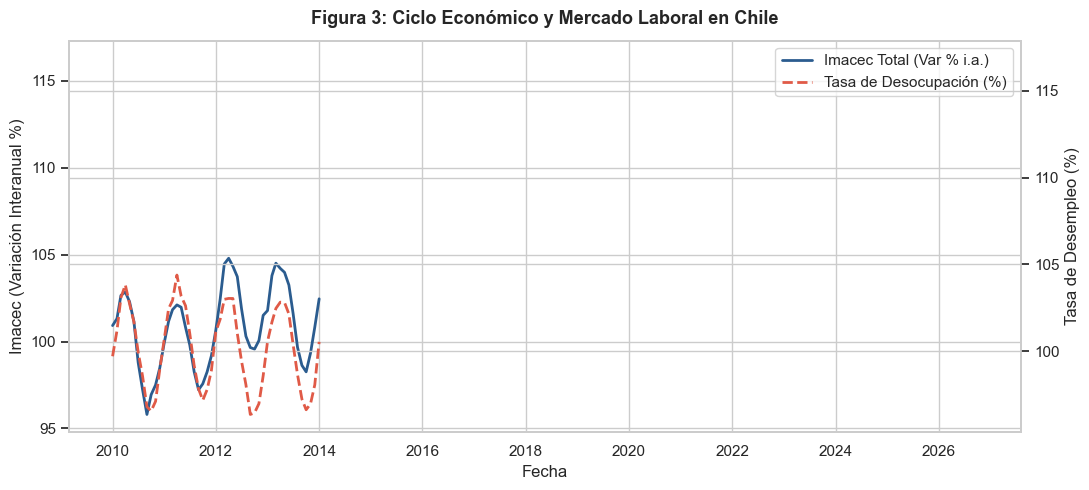

In [23]:
# GRÁFICO 3: Actividad Económica (Imacec) vs Mercado Laboral
fig, ax3_left = plt.subplots(figsize=(11, 5))
ax3_right = ax3_left.twinx()

if col_imacec in df_coyuntura.columns:
    ax3_left.plot(df_coyuntura.index, df_coyuntura[col_imacec], label='Imacec Total (Var % i.a.)', color='#2b5c8f', linewidth=2)
if col_desempleo in df_coyuntura.columns:
    ax3_right.plot(df_coyuntura.index, df_coyuntura[col_desempleo], label='Tasa de Desocupación (%)', color='#e05a47', linestyle='--', linewidth=2)

ax3_left.set_title("Figura 3: Ciclo Económico y Mercado Laboral en Chile", fontsize=13, fontweight='bold', pad=12)
ax3_left.set_ylabel("Imacec (Variación Interanual %)")
ax3_right.set_ylabel("Tasa de Desempleo (%)")
ax3_left.set_xlabel("Fecha")

lines_a, labels_a = ax3_left.get_legend_handles_labels()
lines_b, labels_b = ax3_right.get_legend_handles_labels()
ax3_left.legend(lines_a + lines_b, labels_a + labels_b, loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

###  Análisis de Coyuntura: Figura 3
* **Título:** Ciclo Económico (Imacec) y Holguras del Mercado Laboral.
* **Fuente:** Banco Central de Chile e Instituto Nacional de Estadísticas (INE).
* **Lectura Económica:** 
Esta figura relaciona el ritmo de crecimiento de la actividad económica (Imacec) con el desempeño del mercado laboral. Periodos de desaceleración económica generan holguras de capacidad productiva, lo que impacta de manera rezagada en un incremento de la tasa de desocupación, amortiguando a su vez las presiones de demanda sobre los precios.

In [24]:
# TABLA DE INDICADORES CLAVE PARA REGLA DE TAYLOR Y RESUMEN
df_resumen = df_coyuntura.copy()

# 1. Desvío de Expectativas a 24M respecto a la Meta (3%)
if col_eee in df_resumen.columns:
    df_resumen['Desvio_Expectativas'] = df_resumen[col_eee] - 3.0

# 2. Diferencial de Tasas (TPM Chile - Fed Funds EE.UU.)
if col_tpm in df_resumen.columns and col_fed in df_resumen.columns:
    df_resumen['Diferencial_Tasas'] = df_resumen[col_tpm] - df_resumen[col_fed]

cols_mostrar = [c for c in [col_tpm, col_ipc, col_eee, 'Desvio_Expectativas', 'Diferencial_Tasas'] if c in df_resumen.columns]

print("=== ÚLTIMOS REGISTROS DE COYUNTURA MACROECONÓMICA ===")
print(df_resumen[cols_mostrar].dropna().tail(6))

=== ÚLTIMOS REGISTROS DE COYUNTURA MACROECONÓMICA ===
nombre      Fed Funds Rate (tasa de política EE.UU.)  \
fecha                                                  
2026-05-01                                   114.990   
2026-06-01                                   114.375   
2026-07-01                                   112.500   
2026-08-01                                   111.526   
2026-09-01                                   110.052   
2026-10-01                                   109.774   

nombre      IPC, variación mensual (calcular interanual con LAG 12 en SQL)  \
fecha                                                                        
2026-05-01                                            105.925                
2026-06-01                                            104.953                
2026-07-01                                            103.750                
2026-08-01                                            101.820                
2026-09-01                   